id: http://localhost:8889/lab/tree/01_sky_models.ipynb

<!-- notebooks/01_sky_models.ipynb -- sky models (Interferosim 0.2.1) -->
# 01 – Sky models

This notebook shows how Interferosim describes the sky and how a sky model is displayed as a map.

A sky model consists of a **field centre** (RA/Dec, J2000) and a list of **components**. Their positions are given as offsets `dx_deg` (east) and `dy_deg` (north) from the field centre. The file format is the one of the AAS6 simulation sky (`json/interfero/sim_sky.json`):

| Field | Meaning |
|---|---|
| `center.label`, `ra_deg`, `dec_deg` | name and position of the field centre (J2000, degrees) |
| `name` | name of the source |
| `dx_deg`, `dy_deg` | offset from the centre in degrees (east/north) |
| `flux_jy` | flux density in Jy |
| `kind` | `"point"`, `"gauss"` or `"disc"` (new in Interferosim) |
| `fwhm_x_deg`, `fwhm_y_deg`, `pa_deg` | size (FWHM) and position angle of a `gauss` component |
| `diameter_deg`, `limb`, `limb_power` | diameter and limb brightening $1+\mathrm{limb}\,\rho^{\mathrm{limb\_power}}$ of a `disc` |

Theory: documentation, chapter *Visibility and Source Models*.

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from interferosim.sky import SkyModel, PointSource, GaussianSource, DiscSource, FieldCenter, AS, AM
from interferosim.plotting import plot_sky_map, plot_sky_overview

SKIES = Path("..") / "configs" / "skies"
sorted(p.name for p in SKIES.glob("*.json"))

['aas6_demo.json', 'sun_21cm.json', 'w3oh_masers.json']

## 1. The demo field

The demo field of `aas6sim` around W3(OH): an extended HI base, a galactic bar, two HII regions, a supernova remnant shell, a compact source and three OH masers only a few arcseconds apart.

In [3]:
sky = SkyModel.from_json(SKIES / "aas6_demo.json")
print(f"centre: {sky.center.label}  RA {sky.center.ra_deg} deg  Dec {sky.center.dec_deg} deg")
print(f"{'kind':6s} {'name':<18s} {'dx [deg]':>10s} {'dy [deg]':>10s} {'flux [Jy]':>10s}")
for c in sky:
    print(f"{c.kind:6s} {c.name:<18s} {c.dx_deg:10.5f} {c.dy_deg:10.5f} {c.flux_jy:10.1f}")
print(f"total flux: {sky.total_flux_jy:.1f} Jy")

centre: W3(OH)  RA 36.7661 deg  Dec 61.8742 deg
kind   name                 dx [deg]   dy [deg]  flux [Jy]
gauss  HI base               0.00000    0.00000     1500.0
gauss  Galactic bar          0.00000    0.00000     4000.0
gauss  HII region A         -2.00000    1.20000      900.0
gauss  HII region B          2.60000   -1.60000      550.0
gauss  SNR shell C           1.20000    2.40000      350.0
gauss  Compact source K1    -1.40000   -0.60000      260.0
point  Maser M1              0.30000    0.45000       70.0
point  Maser M2              0.30144    0.44958       45.0
point  Maser M3              0.30389    0.45250       20.0
total flux: 7695.0 Jy


The map shows the brightness in Jy per pixel on a logarithmic scale. Components smaller than a few pixels are marked with circles (area proportional to the flux density). The masers are invisible in the full field; the right panel zooms in on them. East is to the left.

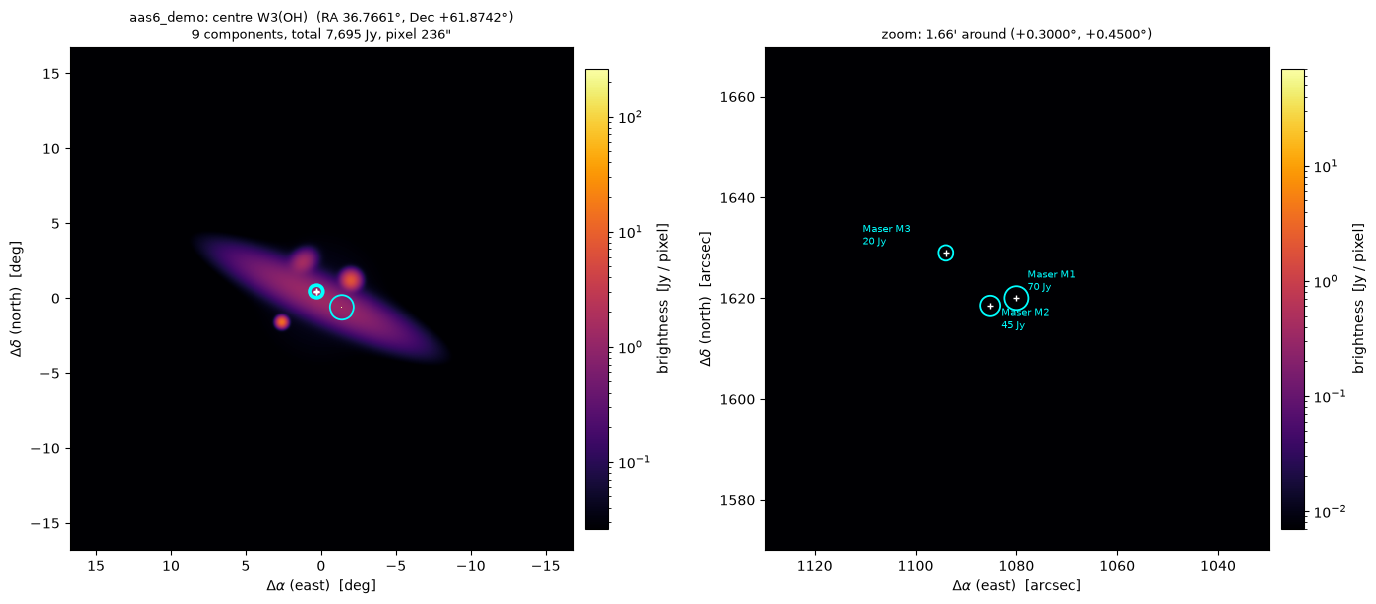

In [4]:
fig, axes = plot_sky_overview(sky)
plt.show()

## 2. The maser group alone

Only the three masers. The map is automatically centred on the components, the axis unit follows the field size (here arcseconds).

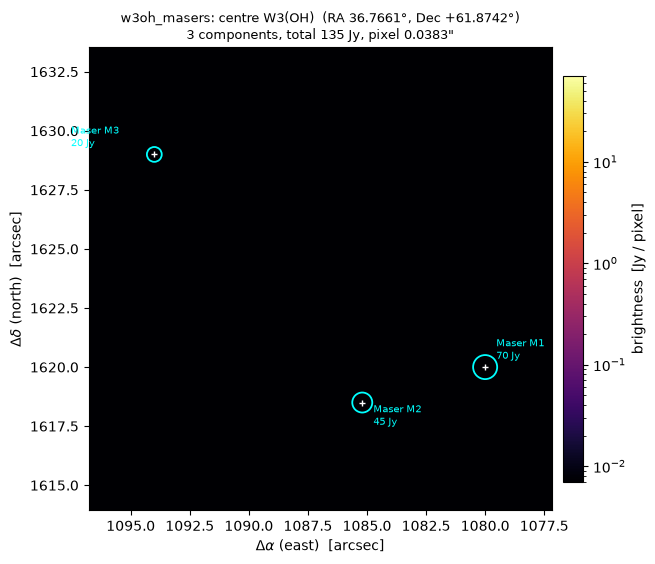

In [5]:
masers = SkyModel.from_json(SKIES / "w3oh_masers.json")
fig, ax, img = plot_sky_map(masers)
plt.show()

## 3. The Sun at 21 cm

A disc of 34′ with limb brightening (+50 %), from notebook B. The linear scale shows the bright rim. The visibility of the disc is computed by a Hankel transform; its first zero lies near $b_{\mathrm{null}} = 1.2197\,\lambda/\theta_d \approx 26$ m.

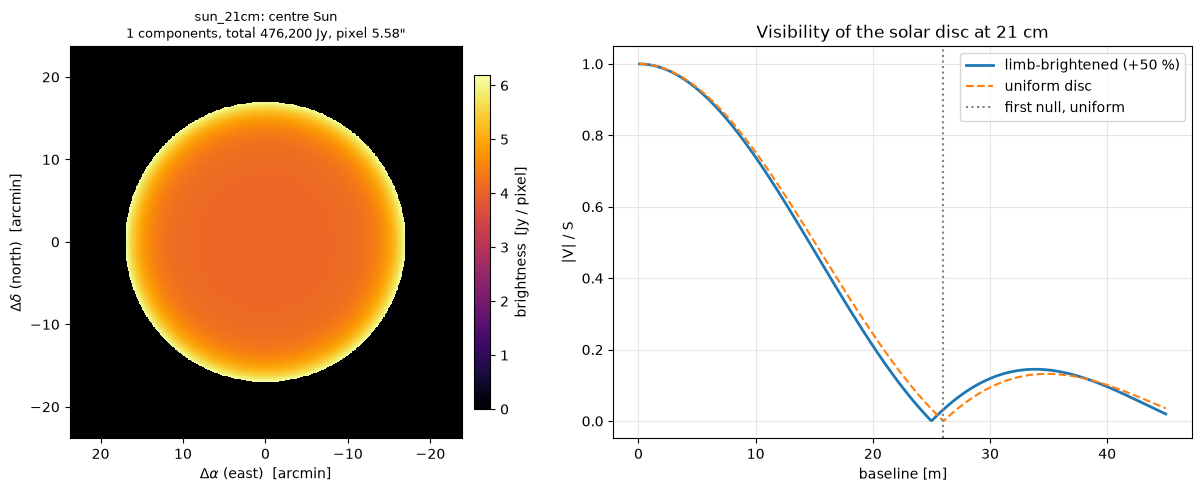

In [6]:
sun = SkyModel.from_json(SKIES / "sun_21cm.json")
disc = sun.components[0]
uniform = DiscSource("uniform", 0, 0, disc.flux_jy, diameter_deg=disc.diameter_deg)

lam = 299_792_458.0 / 1_420_405_751.768
b = np.linspace(0.1, 45, 400)                    # baseline in m (east-west)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
plot_sky_map(sun, scale="linear", ax=ax[0], mark=False)
ax[1].plot(b, np.abs(disc.visibility(b / lam, 0)) / disc.flux_jy, lw=2, label="limb-brightened (+50 %)")
ax[1].plot(b, np.abs(uniform.visibility(b / lam, 0)) / disc.flux_jy, lw=1.5, ls="--", label="uniform disc")
ax[1].axvline(1.2197 * lam / np.radians(disc.diameter_deg), color="0.5", ls=":", label="first null, uniform")
ax[1].set_xlabel("baseline [m]"); ax[1].set_ylabel("|V| / S"); ax[1].grid(alpha=0.3); ax[1].legend()
ax[1].set_title("Visibility of the solar disc at 21 cm")
plt.tight_layout(); plt.show()

## 4. Building your own sky

Components are created in Python and added to a `SkyModel`. The model can be saved in the same JSON format and loaded again (also by AAS6, as long as only `point` and `gauss` are used).

{
  "name": "my_example",
  "center": {
    "label": "Cas A",
    "ra_deg": 350.85,
    "dec_deg": 58.815
  },
  "components": [
    {
      "name": "extended halo",
      "dx_deg": 0.0,
      "dy_deg": 0.0,
      "flux_jy": 300.0,
      "kind": "gauss",
      "fwhm_x_deg": 0.5,
      "fwhm_y_deg": 0.3,
      "pa_deg": 20.0
    },
    {
      "name": "compact A",
      "dx_deg": -0.1,
      "dy_de ...


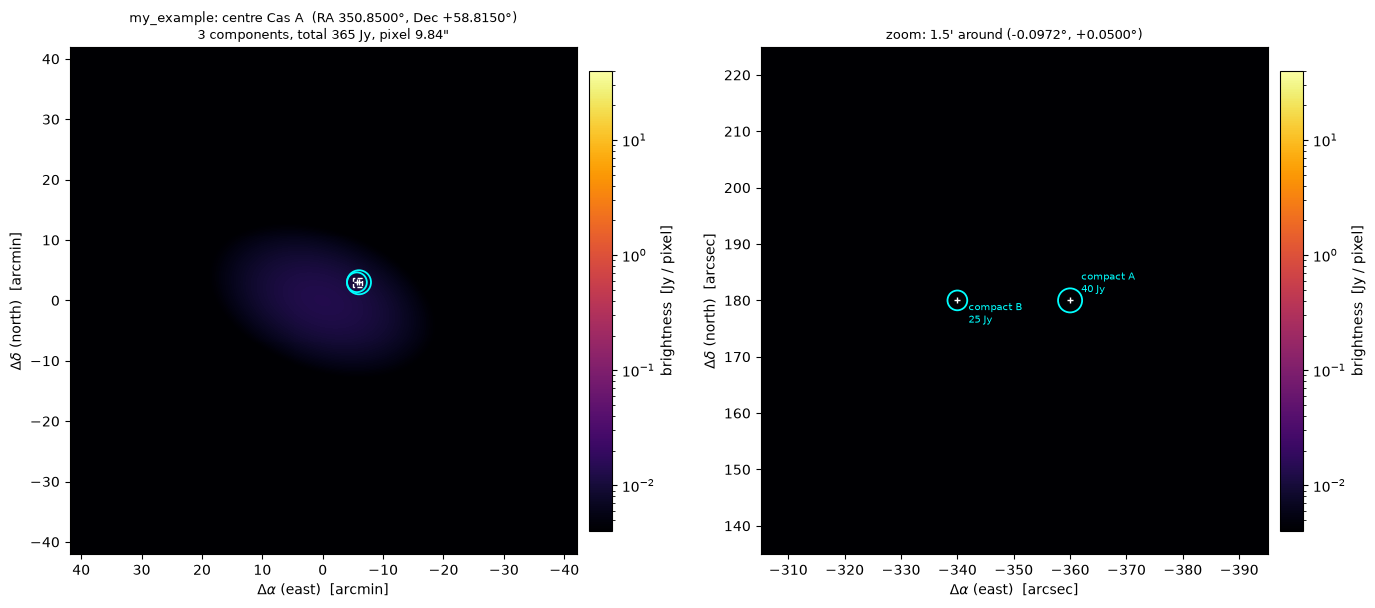

In [7]:
my_sky = SkyModel(center=FieldCenter("Cas A", 350.85, 58.815), name="my_example")
my_sky.add(GaussianSource("extended halo", 0.0, 0.0, 300.0, fwhm_x_deg=0.5, fwhm_y_deg=0.3, pa_deg=20.0))
my_sky.add(PointSource("compact A", -0.10, 0.05, 40.0))
my_sky.add(PointSource("compact B", -0.10 + 20 * AS, 0.05, 25.0))   # 20 arcsec east of A

path = my_sky.to_json("my_example_sky.json")
print(path.read_text()[:400], "...")

fig, axes = plot_sky_overview(SkyModel.from_json(path), zoom_center_deg=(-0.10 + 10 * AS, 0.05), zoom_fov_deg=1.5 * AM)
plt.show()

## 5. From the sky to the visibilities

Every component provides its analytic visibility. The sum over all components is what an interferometer would measure (without noise, primary beam and instrument effects -- these follow in the next steps). Here: visibility amplitude of the demo field along an east-west baseline.

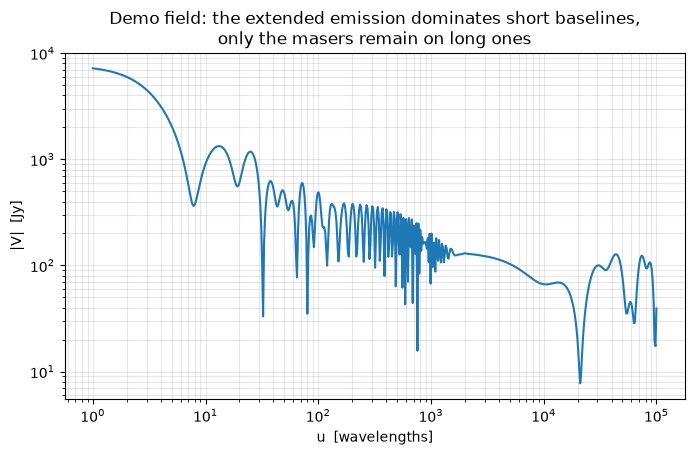

In [7]:
u = np.logspace(0, 5, 600)          # spatial frequency in wavelengths
V = sky.visibility(u, 0.0)
plt.figure(figsize=(8, 4.5))
plt.loglog(u, np.abs(V))
plt.xlabel("u  [wavelengths]"); plt.ylabel("|V|  [Jy]"); plt.grid(alpha=0.3, which="both")
plt.title("Demo field: the extended emission dominates short baselines,\nonly the masers remain on long ones")
plt.show()